<a href="https://colab.research.google.com/github/Pathikrit003/Cervical-Cancer-/blob/main/cervical_cancer_convnextv2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [7]:
!pip install -q timm scikit-learn seaborn matplotlib kagglehub pillow


Running on: cuda (Tesla T4)
Backbone: CONVNEXTV2

Using Colab cache for faster access to the 'cervical-cancer-largest-dataset-sipakmed' dataset.
Dataset downloaded to: /kaggle/input/cervical-cancer-largest-dataset-sipakmed
Total Single-Cell Images Found: 966
Data Split: Train=656, Val=116, Test=194


model.safetensors: reconstructing file:   0%|          |  0.00B /  792MB            

model.safetensors: downloading bytes:           |  0.00B            


--- Starting Training (CONVNEXTV2) ---


Epoch 1/15 [Train]: 100%|██████████| 41/41 [00:49<00:00,  1.20s/it, loss=1.6500]


Epoch 01/15 | Train Loss: 1.9114 | Train Acc: 37.80% | Val Acc: 56.03%
Saved Best Model (Val Acc: 56.03%)


... (26 outputs left out)

Epoch 15/15 [Train]: 100%|██████████| 41/41 [00:31<00:00,  1.29it/s, loss=1.5740]


Epoch 15/15 | Train Loss: 1.2561 | Train Acc: 60.52% | Val Acc: 89.66%


Evaluating Test Set: 100%|██████████| 13/13 [00:10<00:00,  1.25it/s]



 BENCHMARK COMPARISON TABLE 
     Model  Train Acc (%)  Val Acc (%)  Test Acc (%)  Macro Precision  Macro Recall  Macro F1-Score
CONVNEXTV2          60.52        89.66         90.72           0.9109        0.9243          0.9171

Detailed Per-Class Performance:
                          precision    recall  f1-score   support

            Dyskeratotic     0.9348    0.9556    0.9451        45
            Koilocytotic     0.8723    0.8542    0.8632        48
             Metaplastic     0.9020    0.8519    0.8762        54
               Parabasal     0.9565    1.0000    0.9778        22
Superficial-Intermediate     0.8889    0.9600    0.9231        25

                accuracy                         0.9072       194
               macro avg     0.9109    0.9243    0.9171       194
            weighted avg     0.9067    0.9072    0.9065       194



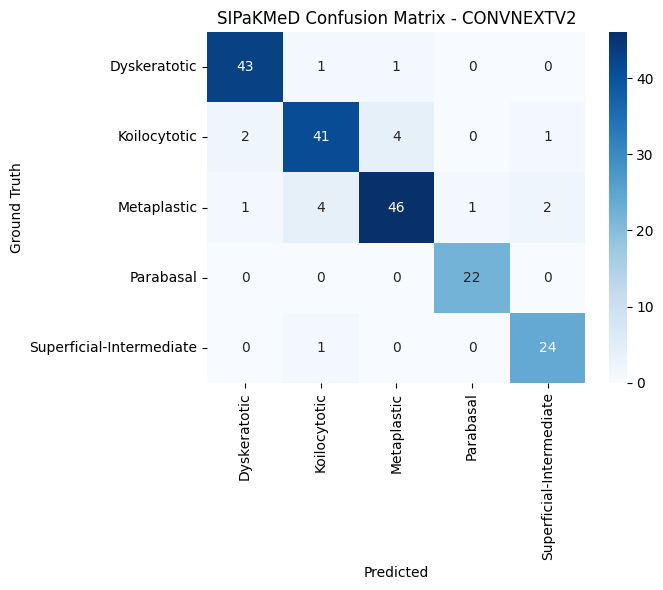

In [8]:
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import warnings
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torch.amp import autocast, GradScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_recall_fscore_support

import timm
from timm.data.mixup import Mixup
from timm.loss import SoftTargetCrossEntropy
import kagglehub

warnings.filterwarnings("ignore")

# ------------------------------------------------------------------------------
# 1. Configuration & Reproducibility
# ------------------------------------------------------------------------------
def seed_everything(seed=42):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

SEED = 42
seed_everything(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
OUTPUT_DIR = "./sipakmed_outputs"
os.makedirs(OUTPUT_DIR, exist_ok=True)


ACTIVE_BACKBONE = 'convnextv2'

IMG_SIZE = 224
BATCH_SIZE = 16
NUM_EPOCHS = 15
INIT_LR = 1e-5
WEIGHT_DECAY = 0.05
NUM_WORKERS = 2

MIXUP_ALPHA = 0.8
CUTMIX_ALPHA = 1.0
LABEL_SMOOTHING = 0.1
CONTRASTIVE_LOSS_WEIGHT = 0.1

CLASS_MAP = {
    'dyskeratotic': 0,
    'koilocytotic': 1,
    'metaplastic': 2,
    'parabasal': 3,
    'superficial-intermediate': 4,
    'superficial': 4,
    'intermediate': 4
}
CLASS_NAMES = ['Dyskeratotic', 'Koilocytotic', 'Metaplastic', 'Parabasal', 'Superficial-Intermediate']
NUM_CLASSES = 5

print(f"Running on: {DEVICE} ({torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'CPU'})")
print(f"Backbone: {ACTIVE_BACKBONE.upper()}")

# ------------------------------------------------------------------------------
# 2. Download & Index SIPaKMeD Dataset
# ------------------------------------------------------------------------------
print("\nDownloading SIPaKMeD dataset via kagglehub...")
dataset_dir = kagglehub.dataset_download("prahladmehandiratta/cervical-cancer-largest-dataset-sipakmed")
print(f"Dataset downloaded to: {dataset_dir}")

records = []
for root, dirs, files in os.walk(dataset_dir):
    folder_lower = os.path.basename(root).lower()
    matched = None
    for k, v in CLASS_MAP.items():
        if k in folder_lower:
            matched = v
            break
    if matched is not None:
        for f in files:
            if f.lower().endswith(('.bmp', '.jpg', '.jpeg', '.png')):
                records.append({'path': os.path.join(root, f), 'label': matched})

df = pd.DataFrame(records).drop_duplicates(subset=['path']).reset_index(drop=True)
print(f"Total Single-Cell Images Found: {len(df)}")

train_df, test_df = train_test_split(df, test_size=0.20, stratify=df['label'], random_state=SEED)
train_df, val_df = train_test_split(train_df, test_size=0.15, stratify=train_df['label'], random_state=SEED)

print(f"Data Split: Train={len(train_df)}, Val={len(val_df)}, Test={len(test_df)}")

# ------------------------------------------------------------------------------
# 3. Augmentation Pipeline
# ------------------------------------------------------------------------------
class TwoRegionRandomErasing:
    def __init__(self, p=0.5, scale=(0.02, 0.33), ratio=(0.3, 3.3), value='random'):
        self.eraser = transforms.RandomErasing(p=1.0, scale=scale, ratio=ratio, value=value)
        self.p = p

    def __call__(self, img):
        if random.random() < self.p:
            img = self.eraser(img)
        if random.random() < self.p:
            img = self.eraser(img)
        return img

train_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(25),
    transforms.RandomAffine(0, scale=(0.75, 1.25)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    TwoRegionRandomErasing(p=0.5, value='random')
])

eval_transforms = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

class SIPaKMeDDataset(Dataset):
    def __init__(self, data_df, transform=None):
        self.df = data_df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img_path = self.df.iloc[idx]['path']
        lbl = int(self.df.iloc[idx]['label'])
        img = Image.open(img_path).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, lbl

train_loader = DataLoader(SIPaKMeDDataset(train_df, train_transforms), batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
val_loader = DataLoader(SIPaKMeDDataset(val_df, eval_transforms), batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
test_loader = DataLoader(SIPaKMeDDataset(test_df, eval_transforms), batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)

mixup_fn = Mixup(
    mixup_alpha=MIXUP_ALPHA,
    cutmix_alpha=CUTMIX_ALPHA,
    label_smoothing=LABEL_SMOOTHING,
    num_classes=NUM_CLASSES
)

# ------------------------------------------------------------------------------
# 4. Model Architecture with Dual Heads
# ------------------------------------------------------------------------------
class BenchmarkModel(nn.Module):
    def __init__(self, backbone_type='eva02', num_classes=5, pretrained=True):
        super().__init__()
        self.backbone_type = backbone_type

        if backbone_type == 'eva02':
            self.backbone = timm.create_model('eva02_large_patch14_224', pretrained=pretrained)
            self.backbone.head = nn.Identity()
            backbone_dim = self.backbone.embed_dim
        elif backbone_type == 'beitv2':
            self.backbone = timm.create_model('beitv2_large_patch16_224', pretrained=pretrained)
            self.backbone.head = nn.Identity()
            backbone_dim = self.backbone.embed_dim
        elif backbone_type == 'convnextv2':
            self.backbone = timm.create_model('convnextv2_large.fcmae_ft_in1k', pretrained=pretrained)
            self.backbone.head = nn.Identity()
            backbone_dim = self.backbone.num_features

        self.head = nn.Linear(backbone_dim, num_classes)
        self.contrastive_head = nn.Sequential(
            nn.LayerNorm(backbone_dim),
            nn.Linear(backbone_dim, 128)
        )

    def forward(self, x):
        features = self.backbone.forward_features(x)
        if self.backbone_type in ['eva02', 'beitv2']:
            pooled_output = features.mean(dim=1)
        elif self.backbone_type == 'convnextv2':
            pooled_output = features.mean(dim=[2, 3])

        logits = self.head(pooled_output)
        contrastive_features = self.contrastive_head(pooled_output)
        return logits, F.normalize(contrastive_features, dim=1)

model = BenchmarkModel(backbone_type=ACTIVE_BACKBONE, num_classes=NUM_CLASSES, pretrained=True).to(DEVICE)

# ------------------------------------------------------------------------------
# 5. Dual Loss Functions (CrossEntropy + SupConLoss)
# ------------------------------------------------------------------------------
class SupConLoss(nn.Module):
    def __init__(self, temperature=0.07):
        super().__init__()
        self.temperature = temperature

    def forward(self, features, labels):
        batch_size = features.shape[0]
        labels = labels.contiguous().view(-1, 1)
        mask = torch.eq(labels, labels.T).float().to(features.device)

        anchor_dot_contrast = torch.div(torch.matmul(features, features.T), self.temperature)
        logits_max, _ = torch.max(anchor_dot_contrast, dim=1, keepdim=True)
        logits = anchor_dot_contrast - logits_max.detach()

        logits_mask = torch.scatter(
            torch.ones_like(mask), 1,
            torch.arange(batch_size).view(-1, 1).to(features.device), 0
        )
        mask = mask * logits_mask
        exp_logits = torch.exp(logits) * logits_mask
        log_prob = logits - torch.log(exp_logits.sum(1, keepdim=True) + 1e-6)

        mask_sum = mask.sum(1)
        mean_log_prob_pos = (mask * log_prob).sum(1) / (mask_sum + 1e-6)
        return -mean_log_prob_pos.mean()

classification_loss_fn = SoftTargetCrossEntropy().to(DEVICE)
contrastive_loss_fn = SupConLoss().to(DEVICE)

# ------------------------------------------------------------------------------
# 6. Training & Validation Loop
# ------------------------------------------------------------------------------
optimizer = optim.AdamW(model.parameters(), lr=INIT_LR, weight_decay=WEIGHT_DECAY)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS, eta_min=1e-7)
scaler = GradScaler('cuda')
best_val_acc = 0.0
best_model_path = os.path.join(OUTPUT_DIR, f"best_{ACTIVE_BACKBONE}_sipakmed.pth")

print(f"\n--- Starting Training ({ACTIVE_BACKBONE.upper()}) ---")

for epoch in range(NUM_EPOCHS):
    model.train()
    total_train_loss = 0.0
    train_correct = 0
    train_total = 0

    pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{NUM_EPOCHS} [Train]")
    for images, labels in pbar:
        original_labels = labels.clone().to(DEVICE)
        images, labels = images.to(DEVICE), labels.to(DEVICE)
        images, labels = mixup_fn(images, labels)

        optimizer.zero_grad()
        with autocast('cuda'):
            logits, features = model(images)
            loss_cls = classification_loss_fn(logits, labels)
            loss_con = contrastive_loss_fn(features, original_labels)
            loss = loss_cls + (loss_con * CONTRASTIVE_LOSS_WEIGHT)

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        total_train_loss += loss.item()
        train_total += original_labels.size(0)
        train_correct += (logits.argmax(1) == original_labels).sum().item()
        pbar.set_postfix(loss=f"{loss.item():.4f}")

    scheduler.step()
    train_acc = (train_correct / train_total) * 100
    avg_train_loss = total_train_loss / len(train_loader)

    # Validation
    model.eval()
    val_correct, val_total = 0, 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(DEVICE), labels.to(DEVICE)
            with autocast('cuda'):
                logits, _ = model(images)
            val_total += labels.size(0)
            val_correct += (logits.argmax(1) == labels).sum().item()

    val_acc = (val_correct / val_total) * 100
    print(f"Epoch {epoch+1:02d}/{NUM_EPOCHS} | Train Loss: {avg_train_loss:.4f} | Train Acc: {train_acc:.2f}% | Val Acc: {val_acc:.2f}%")

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        torch.save(model.state_dict(), best_model_path)
        print(f"Saved Best Model (Val Acc: {best_val_acc:.2f}%)")

# ------------------------------------------------------------------------------
# 7. Final Test Evaluation & Metrics Table
# ------------------------------------------------------------------------------
eval_model = BenchmarkModel(backbone_type=ACTIVE_BACKBONE, num_classes=NUM_CLASSES)
eval_model.load_state_dict(torch.load(best_model_path))
eval_model.to(DEVICE)
eval_model.eval()

y_true, y_pred = [], []
with torch.no_grad():
    for images, labels in tqdm(test_loader, desc="Evaluating Test Set"):
        images = images.to(DEVICE)
        with autocast('cuda'):
            logits, _ = eval_model(images)
        y_true.extend(labels.numpy())
        y_pred.extend(logits.argmax(1).cpu().numpy())

test_acc = accuracy_score(y_true, y_pred)
prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="macro", zero_division=0)

summary_table = pd.DataFrame([{
    "Model": f"{ACTIVE_BACKBONE.upper()}",
    "Train Acc (%)": round(train_acc, 2),
    "Val Acc (%)": round(best_val_acc, 2),
    "Test Acc (%)": round(test_acc * 100, 2),
    "Macro Precision": round(prec, 4),
    "Macro Recall": round(rec, 4),
    "Macro F1-Score": round(f1, 4)
}])

print("\n" + "=" * 50)
print(" BENCHMARK COMPARISON TABLE ")
print("=" * 50)
print(summary_table.to_string(index=False))

print("\nDetailed Per-Class Performance:")
print(classification_report(y_true, y_pred, target_names=CLASS_NAMES, digits=4))

# Confusion Matrix Heatmap
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.title(f"SIPaKMeD Confusion Matrix - {ACTIVE_BACKBONE.upper()}")
plt.xlabel("Predicted")
plt.ylabel("Ground Truth")
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, f"{ACTIVE_BACKBONE}_confusion_matrix.png"), dpi=300)
plt.show()